In [17]:
import pandas as pd

# By setting on_bad_lines='skip', we can parse the CSV normally and skip any malformed rows
df = pd.read_csv("/content/athlete_events(1).csv", on_bad_lines='skip')

print(df.shape)
df.head()

(271116, 15)


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  object 
 2   Sex     271116 non-null  object 
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  object 
 7   NOC     271116 non-null  object 
 8   Games   271116 non-null  object 
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  object 
 11  City    271116 non-null  object 
 12  Sport   271116 non-null  object 
 13  Event   271116 non-null  object 
 14  Medal   39783 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 31.0+ MB


In [20]:
df.isnull().sum()

,0
ID,0
Name,0
Sex,0
Age,9474
Height,60171
Weight,62875
Team,0
NOC,0
Games,0
Year,0


In [21]:
  missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.round(2))

ID         0.00
Name       0.00
Sex        0.00
Age        3.49
Height    22.19
Weight    23.19
Team       0.00
NOC        0.00
Games      0.00
Year       0.00
Season     0.00
City       0.00
Sport      0.00
Event      0.00
Medal     85.33
dtype: float64


In [22]:
df.duplicated().sum()

np.int64(1385)

In [23]:
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())

Original rows: 271116
Cleaned rows: 269731
Duplicates remaining: 0


In [24]:
df_clean["Medal"] = df_clean["Medal"].fillna("No Medal")

df_clean["Medal"].value_counts()

,count
Medal,
No Medal,229959
Gold,13369
Bronze,13295
Silver,13108


In [25]:
df_clean[["Age", "Height", "Weight"]].isnull().sum()

,0
Age,9315
Height,58814
Weight,61527


In [26]:
total_records = len(df_clean)

total_athletes = df_clean["ID"].nunique()

total_sports = df_clean["Sport"].nunique()

total_nocs = df_clean["NOC"].nunique()

print("Total Participation Records:", total_records)
print("Total Unique Athletes:", total_athletes)
print("Total Sports:", total_sports)
print("Total NOCs:", total_nocs)

Total Participation Records: 269731
Total Unique Athletes: 135571
Total Sports: 66
Total NOCs: 230


In [28]:
yearly_participation = (
    df_clean.groupby("Year")["ID"]
    .nunique()
    .reset_index(name="Total_Athletes")
)

yearly_participation.head(10)

,Year,Total_Athletes
0,1896,176
1,1900,1224
2,1904,650
3,1906,841
4,1908,2024
5,1912,2409
6,1920,2676
7,1924,3565
8,1928,3703
9,1932,2174


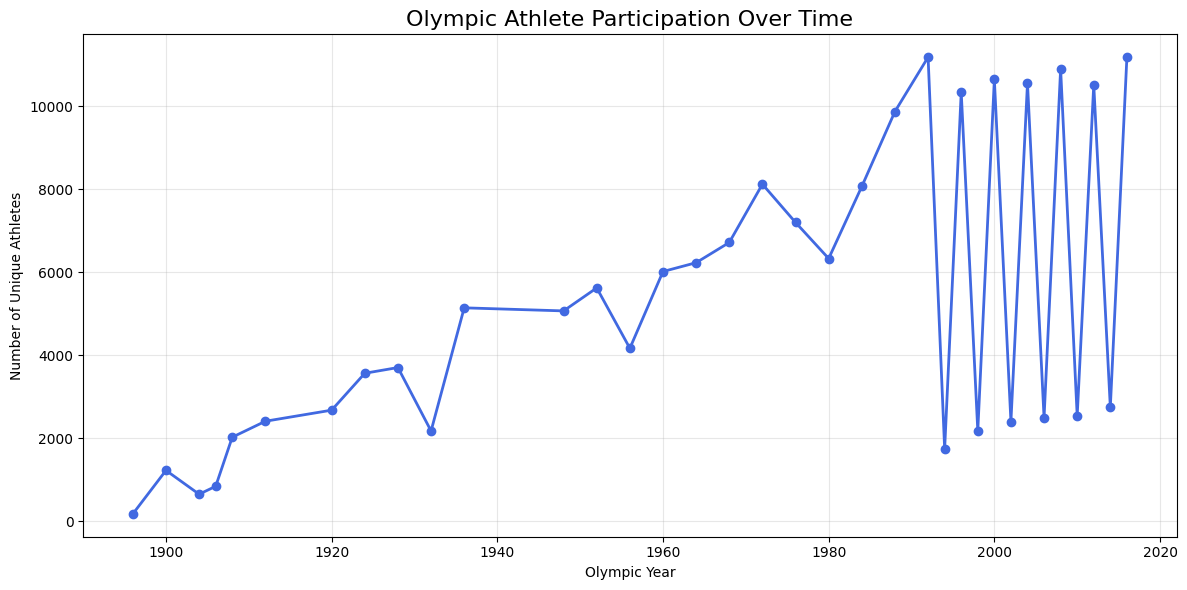

In [29]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_participation["Year"],
    yearly_participation["Total_Athletes"],
    marker="o",
    color="royalblue",
    linewidth=2
)

plt.title("Olympic Athlete Participation Over Time", fontsize=16)
plt.xlabel("Olympic Year")
plt.ylabel("Number of Unique Athletes")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:
gender_participation = (
    df_clean.groupby("Sex")["ID"]
    .nunique()
    .reset_index(name="Total_Athletes")
)

gender_participation

,Sex,Total_Athletes
0,F,33981
1,M,101590


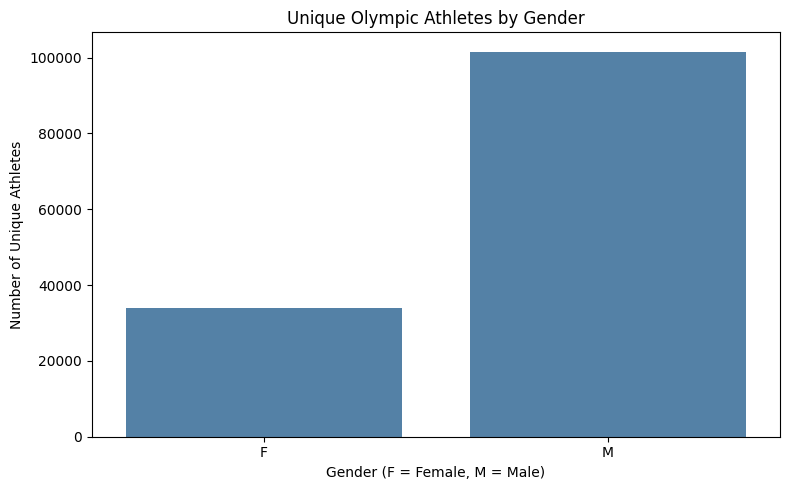

In [31]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_participation,
    x="Sex",
    y="Total_Athletes",
    color="steelblue"
)

plt.title("Unique Olympic Athletes by Gender")
plt.xlabel("Gender (F = Female, M = Male)")
plt.ylabel("Number of Unique Athletes")

plt.tight_layout()
plt.show()


In [32]:
gender_yearly = (
    df_clean.groupby(["Year", "Sex"])["ID"]
    .nunique()
    .reset_index(name="Total_Athletes")
)

gender_yearly.head(10)

,Year,Sex,Total_Athletes
0,1896,M,176
1,1900,F,23
2,1900,M,1201
3,1904,F,6
4,1904,M,644
5,1906,F,6
6,1906,M,835
7,1908,F,44
8,1908,M,1980
9,1912,F,53


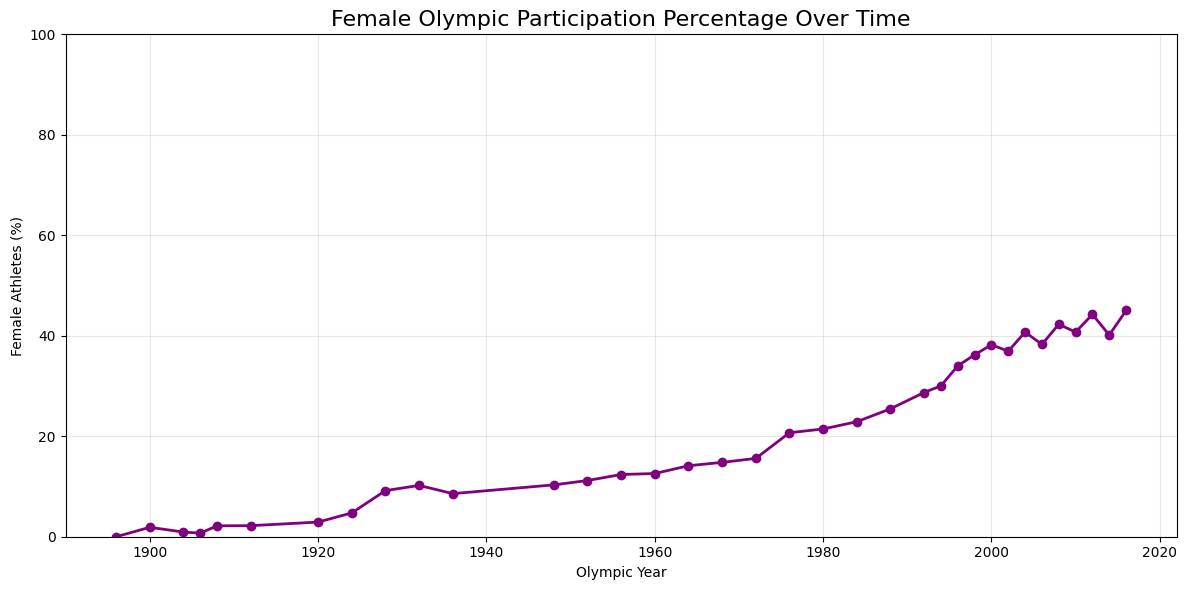

In [35]:
import matplotlib.pyplot as plt

# 1. Pivot the gender_yearly data so that 'F' and 'M' become columns
gender_pivot = gender_yearly.pivot(index="Year", columns="Sex", values="Total_Athletes").fillna(0)

# 2. Calculate total athletes per year and the female percentage
gender_pivot["Total"] = gender_pivot["F"] + gender_pivot["M"]
gender_pivot["Female_Percentage"] = (gender_pivot["F"] / gender_pivot["Total"]) * 100

# 3. Plot the female participation percentage over time
plt.figure(figsize=(12, 6))
plt.plot(
    gender_pivot.index,
    gender_pivot["Female_Percentage"],
    marker="o",
    color="purple",
    linewidth=2
)

plt.title("Female Olympic Participation Percentage Over Time", fontsize=16)
plt.xlabel("Olympic Year")
plt.ylabel("Female Athletes (%)")
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
top_sports = (
    df_clean.groupby("Sport")["ID"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Total_Athletes")
)

top_sports

,Sport,Total_Athletes
0,Athletics,22071
1,Swimming,8765
2,Rowing,7687
3,Football,6161
4,Cycling,5819
5,Boxing,5262
6,Wrestling,4988
7,Shooting,4882
8,Sailing,4480
9,Gymnastics,4134


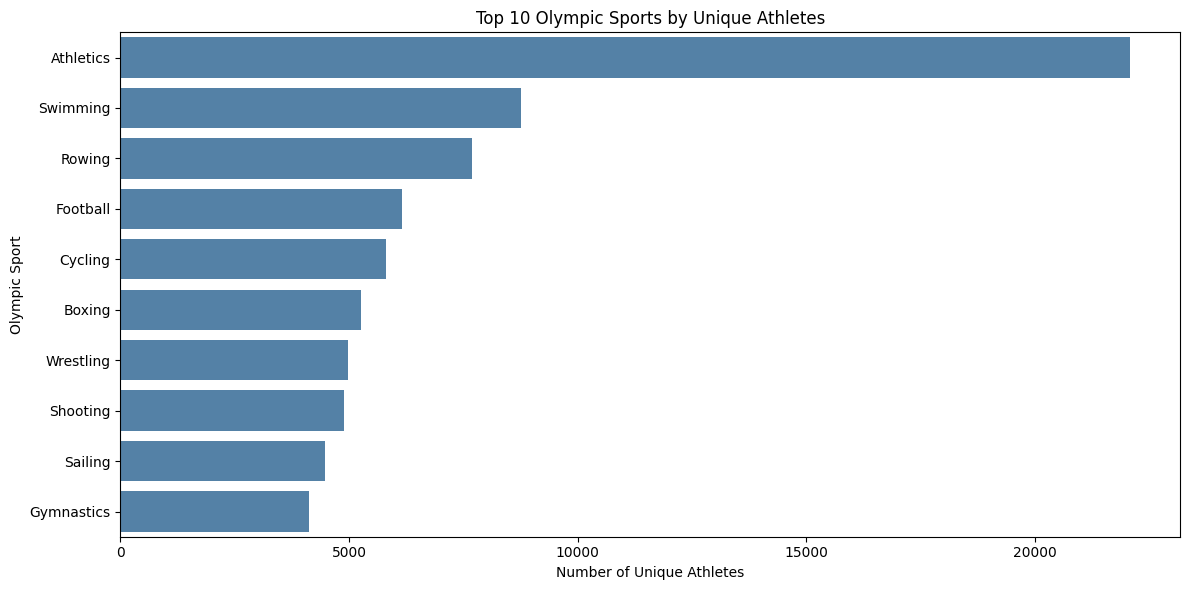

In [37]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_sports,
    x="Total_Athletes",
    y="Sport",
    color="steelblue"
)

plt.title("Top 10 Olympic Sports by Unique Athletes")
plt.xlabel("Number of Unique Athletes")
plt.ylabel("Olympic Sport")

plt.tight_layout()
plt.show()


In [38]:
  print("Sport with highest participation:")
print(top_sports.iloc[0])

Sport with highest participation:
Sport             Athletics
Total_Athletes        22071
Name: 0, dtype: object


In [39]:
medal_counts = (
    df_clean["Medal"]
    .value_counts()
)

print(medal_counts)

Medal
No Medal    229959
Gold         13369
Bronze       13295
Silver       13108
Name: count, dtype: int64


In [40]:
medal_distribution = (
    df_clean[df_clean["Medal"] != "No Medal"]["Medal"]
    .value_counts()
    .reindex(["Gold", "Silver", "Bronze"])
)

print(medal_distribution)

Medal
Gold      13369
Silver    13108
Bronze    13295
Name: count, dtype: int64


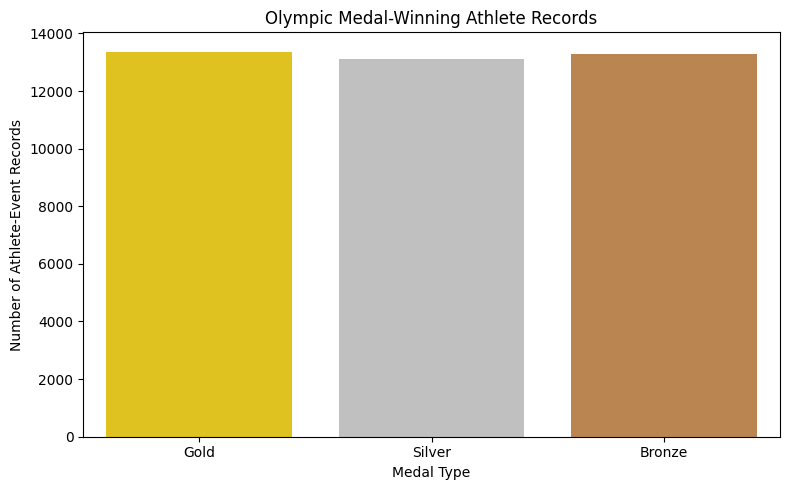

In [41]:

plt.figure(figsize=(8, 5))

sns.barplot(
    x=medal_distribution.index,
    y=medal_distribution.values,
    palette=["gold", "silver", "peru"],
    hue=medal_distribution.index,
    legend=False
)

plt.title("Olympic Medal-Winning Athlete Records")
plt.xlabel("Medal Type")
plt.ylabel("Number of Athlete-Event Records")

plt.tight_layout()
plt.show()


In [42]:
top_nocs = (
    df_clean[df_clean["Medal"] != "No Medal"]
    .groupby("NOC")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Medal_Records")
)

top_nocs

,NOC,Medal_Records
0,USA,5637
1,URS,2503
2,GER,2165
3,GBR,2067
4,FRA,1767
5,ITA,1637
6,SWE,1536
7,CAN,1352
8,AUS,1320
9,RUS,1165


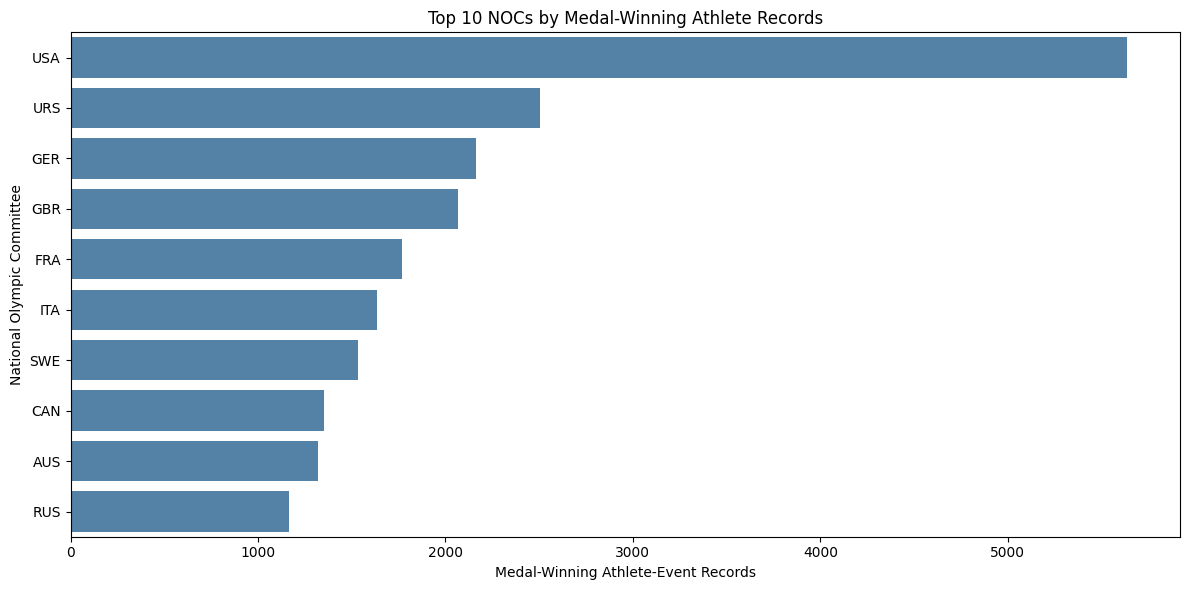

In [43]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_nocs,
    x="Medal_Records",
    y="NOC",
    color="steelblue"
)

plt.title("Top 10 NOCs by Medal-Winning Athlete Records")
plt.xlabel("Medal-Winning Athlete-Event Records")
plt.ylabel("National Olympic Committee")

plt.tight_layout()
plt.show()


In [44]:
india_medals = df_clean[
    (df_clean["NOC"] == "IND") &
    (df_clean["Medal"] != "No Medal")
].copy()

india_medals.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
4732,2699,Shaukat Ali,M,30.0,NaN,NaN,India,IND,1928 Summer,1928,Summer,Amsterdam,Hockey,Hockey Men's Hockey,Gold
4736,2703,Syed Mushtaq Ali,M,22.0,165.0,61.0,India,IND,1964 Summer,1964,Summer,Tokyo,Hockey,Hockey Men's Hockey,Gold
5032,2864,Richard James Allen,M,25.0,172.0,NaN,India,IND,1928 Summer,1928,Summer,Amsterdam,Hockey,Hockey Men's Hockey,Gold
5033,2864,Richard James Allen,M,30.0,172.0,NaN,India,IND,1932 Summer,1932,Summer,Los Angeles,Hockey,Hockey Men's Hockey,Gold
5034,2864,Richard James Allen,M,34.0,172.0,NaN,India,IND,1936 Summer,1936,Summer,Berlin,Hockey,Hockey Men's Hockey,Gold


In [45]:
india_medal_counts = (
    india_medals["Medal"]
    .value_counts()
    .reindex(["Gold", "Silver", "Bronze"], fill_value=0)
)

print(india_medal_counts)

Medal
Gold      138
Silver     19
Bronze     40
Name: count, dtype: int64


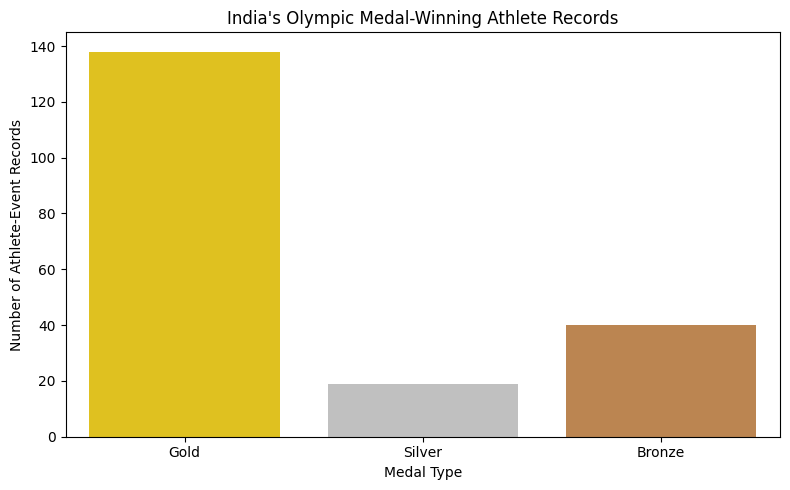

In [46]:

plt.figure(figsize=(8, 5))

sns.barplot(
    x=india_medal_counts.index,
    y=india_medal_counts.values,
    hue=india_medal_counts.index,
    palette=["gold", "silver", "peru"],
    legend=False
)

plt.title("India's Olympic Medal-Winning Athlete Records")
plt.xlabel("Medal Type")
plt.ylabel("Number of Athlete-Event Records")

plt.tight_layout()
plt.show()


In [47]:
india_yearly = (
    india_medals.groupby(["Year", "Medal"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Gold", "Silver", "Bronze"], fill_value=0)
)

india_yearly.head(10)

Medal,Gold,Silver,Bronze
Year,,,
1900,0,2,0
1924,7,0,0
1928,14,0,0
1932,15,0,0
1936,19,0,0
1948,20,0,0
1952,14,0,1
1956,17,0,0
1960,0,13,0


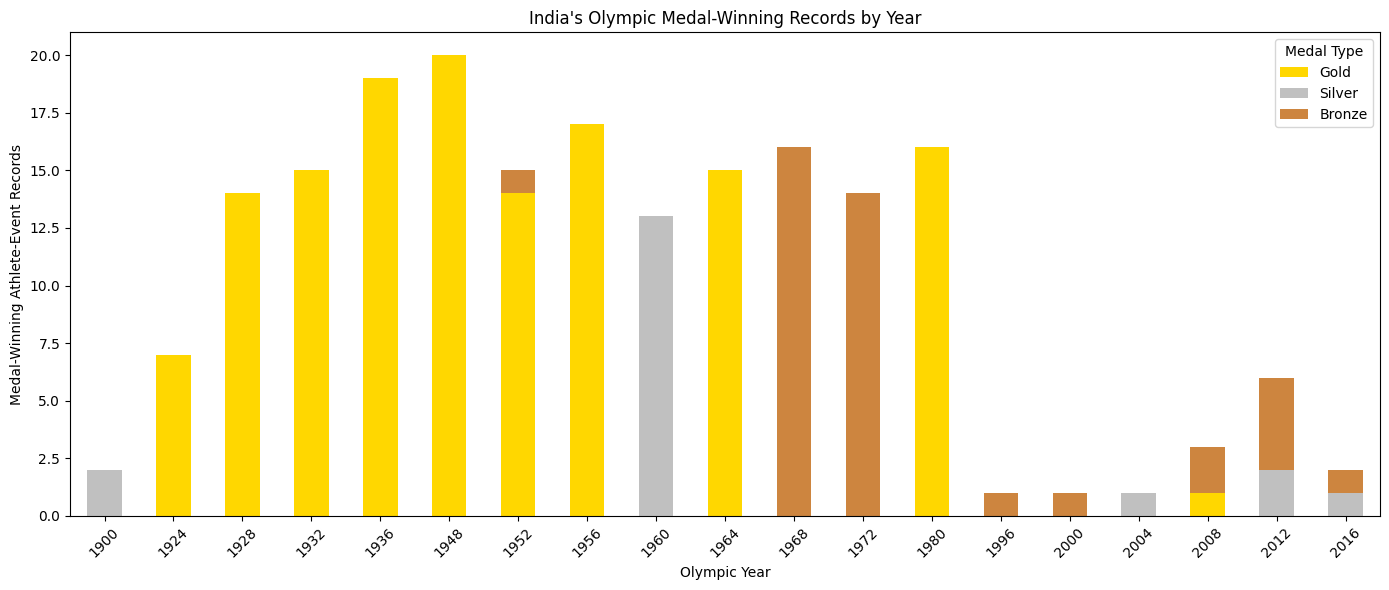

In [48]:

import matplotlib.pyplot as plt

india_yearly.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6),
    color=["gold", "silver", "peru"]
)

plt.title("India's Olympic Medal-Winning Records by Year")
plt.xlabel("Olympic Year")
plt.ylabel("Medal-Winning Athlete-Event Records")
plt.legend(title="Medal Type")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [51]:

print("OLYMPICS DATA ANALYSIS - KEY FINDINGS")
print("------------------------------------")

print("Total unique athletes:", df_clean["ID"].nunique())

print("Total sports:", df_clean["Sport"].nunique())

print("Most participated sport:", top_sports.iloc[0]["Sport"])

print("Top NOC by medal-winning records:", top_nocs.iloc[0]["NOC"])

print("Female participation in earliest recorded year:")
print(round(gender_pivot["Female_Percentage"].iloc[0], 2), "%")

print("Female participation in latest recorded year:")
print(round(gender_pivot["Female_Percentage"].iloc[-1], 2), "%")

print("India's total medal-winning athlete records:", len(india_medals))


OLYMPICS DATA ANALYSIS - KEY FINDINGS
------------------------------------
Total unique athletes: 135571
Total sports: 66
Most participated sport: Athletics
Top NOC by medal-winning records: USA
Female participation in earliest recorded year:
0.0 %
Female participation in latest recorded year:
45.03 %
India's total medal-winning athlete records: 197
